1) Install libraries (run once)

In [1]:
!pip -q install shap lime dice-ml captum gradio

2. Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    precision_score, recall_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from matplotlib.colors import ListedColormap

import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from captum.attr import IntegratedGradients

import dice_ml
from dice_ml import Dice

3) Load data + rename columns + encode target

In [3]:
# Load the dataset# Update this path to where your Heart_disease_clean.csv is locatedDATA_PATH = "Heart_disease_clean.csv"  # If in same directory as notebook# Or use absolute path: DATA_PATH = "C:/path/to/your/Heart_disease_clean.csv"data_raw = pd.read_csv(DATA_PATH)print("Raw shape:", data_raw.shape)print(data_raw.head())print(list(data_raw.columns))

In [4]:
# Cell 3: Load the dataset
DATA_PATH = "Heart_disease_clean.csv"  
data_raw = pd.read_csv(DATA_PATH)
print("Raw shape:", data_raw.shape)
print(data_raw.head())
print(list(data_raw.columns))

Raw shape: (68653, 11)
   Gender (0: female, 1: male)  age(years)        BMI  \
0                            1          50  21.967120   
1                            0          55  34.927679   
2                            0          52  23.507805   
3                            1          48  28.710479   
4                            0          48  23.011177   

   ap_hi(Systolic blood pressure)  ap_lo(Diastolic blood pressure)  \
0                             110                               80   
1                             140                               90   
2                             130                               70   
3                             150                              100   
4                             100                               60   

   cholesterol(1: normal, 2: above normal, 3: well above normal)  \
0                                                  1               
1                                                  3               
2        

In [5]:
# Cell 4: Rename columns and encode target
data = data_raw.rename(columns={
    'Gender (0: female, 1: male)' : 'Gender',
    'age(years)'                  : 'Age',
    'BMI'                         : 'BMI',
    'ap_hi(Systolic blood pressure)'  : 'SBP',
    'ap_lo(Diastolic blood pressure)' : 'DBP',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)' : 'Cholesterol',
    'Glucose(1: normal, 2: above normal, 3: well above normal)'     : 'Glucose',
    'cardiovascular disease'      : 'CVD_text'
})

data['CVD'] = (data['CVD_text'].astype(str).str.lower().str.contains("has")).astype(int)
print(data[['CVD_text','CVD']].head())
print("Target distribution:\n", data['CVD'].value_counts())

                               CVD_text  CVD
0  does not have cardiovascular disease    0
1            has cardiovascular disease    1
2            has cardiovascular disease    1
3            has cardiovascular disease    1
4  does not have cardiovascular disease    0
Target distribution:
 CVD
0    34706
1    33947
Name: count, dtype: int64


# 4. Basic data check and recommended cleaning

4.1 Check ranges

In [6]:
print(data[['Age','BMI','SBP','DBP']].describe())

                Age           BMI           SBP           DBP
count  68653.000000  68653.000000  68653.000000  68653.000000
mean      53.325463     27.518938    126.561374     81.297423
std        6.768377      6.048766     16.510596      9.397980
min       30.000000      3.471784     80.000000     40.000000
25%       48.000000     23.875115    120.000000     80.000000
50%       54.000000     26.346494    120.000000     80.000000
75%       58.000000     30.119376    140.000000     90.000000
max       65.000000    298.666667    200.000000    130.000000


4.2 Clean outliers

In [7]:
df = data.copy()

# Drop missing values for core columns
needed = ['Gender','Age','BMI','SBP','DBP','Cholesterol','Glucose','smoking','alcohol','active','CVD']
df = df.dropna(subset=needed)

# Plausible ranges
df = df[
    (df['BMI'] >= 12) & (df['BMI'] <= 60) &
    (df['SBP'] >= 80) & (df['SBP'] <= 260) &
    (df['DBP'] >= 40) & (df['DBP'] <= 140)
]

# SBP must be greater than DBP
df = df[df['SBP'] > df['DBP']]

print("After cleaning, shape:", df.shape)
print(df['CVD'].value_counts())

After cleaning, shape: (68532, 12)
CVD
0    34648
1    33884
Name: count, dtype: int64


5. Feature engineering (Pulse Pressure, MAP, risk count)

In [8]:
df['PP']  = df['SBP'] - df['DBP']                 # pulse pressure
df['MAP'] = (df['SBP'] + 2*df['DBP']) / 3.0       # mean arterial pressure

df['risk_count'] = (
    (df['Cholesterol'] > 1).astype(int) +
    (df['Glucose'] > 1).astype(int) +
    df['smoking'].astype(int) +
    df['alcohol'].astype(int) +
    (1 - df['active'].astype(int))
)

print(df[['PP','MAP','risk_count']].describe())

                 PP           MAP    risk_count
count  68532.000000  68532.000000  68532.000000
mean      45.325293     96.374409      0.737422
std       11.554263     10.900085      0.878685
min        5.000000     53.333333      0.000000
25%       40.000000     93.333333      0.000000
50%       40.000000     93.333333      1.000000
75%       50.000000    103.333333      1.000000
max      135.000000    153.333333      5.000000


6. Final features (10 base + 3 engineered = 13)


In [9]:
base_features = [
    "Gender","Age","BMI","SBP","DBP",
    "Cholesterol","Glucose","smoking","alcohol","active"
]
engineered_features = ["PP","MAP","risk_count"]

feature_cols = base_features + engineered_features
target_col = "CVD"

X = df[feature_cols].copy()
y = df[target_col].astype(int).copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class labels:", np.unique(y))

X shape: (68532, 13)
y shape: (68532,)
Class labels: [0 1]


7. Correlation heatmap (EDA)

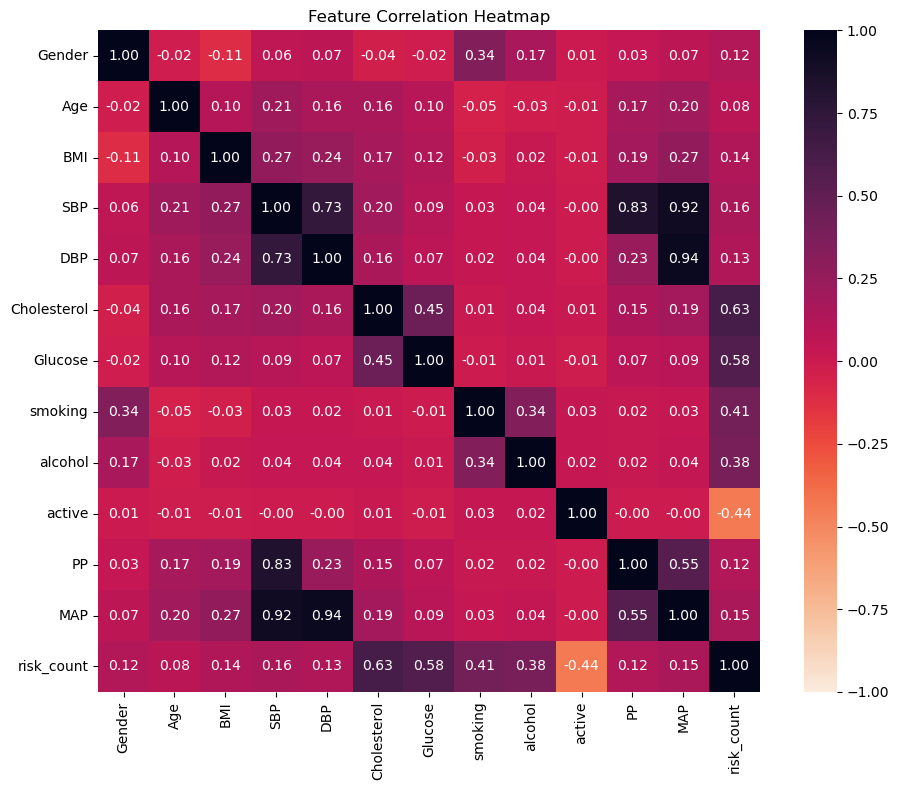

In [10]:
corr = X.corr()

rocket_cmap = sns.color_palette("rocket", as_cmap=True).reversed()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap=rocket_cmap,
    vmin=-1, vmax=1,
    square=True
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

8. Train / validation / test split (70% / 15% / 15%)

In [11]:
# First: 15% test, 85% temp
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Then: from the remaining 85%, split into 70% train and 15% validation
# 0.15 / 0.85 ≈ 0.1765
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1765,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

Train: (47970, 13)
Val  : (10282, 13)
Test : (10280, 13)


# 8) Baseline models (DT, NB, kNN, LR, RF, SVM, MLP) + comparison table

8.1 Helper function to evaluate any model

In [12]:
def eval_on_val_and_test(name, fitted_model,
                         X_val, y_val,
                         X_test, y_test):
    """Return a dict of metrics for a fitted classifier."""
    y_val_proba  = fitted_model.predict_proba(X_val)[:, 1]
    y_val_pred   = fitted_model.predict(X_val)

    y_test_proba = fitted_model.predict_proba(X_test)[:, 1]
    y_test_pred  = fitted_model.predict(X_test)

    return {
        "Model": name,
        "Val AUC":  roc_auc_score(y_val,  y_val_proba),
        "Val acc":  accuracy_score(y_val,  y_val_pred),
        "Val F1":   f1_score(y_val,  y_val_pred),
        "Test AUC": roc_auc_score(y_test, y_test_proba),
        "Test acc": accuracy_score(y_test, y_test_pred),
        "Test F1":  f1_score(y_test, y_test_pred),
    }

Hyperparameter tuning using optuna

In [13]:
# Install Optuna
!pip install -q optuna

import optuna
from optuna.samplers import TPESampler
import warnings
warnings.filterwarnings('ignore')

# Check if GPU is available (for future deep learning models)
import torch
if torch.cuda.is_available():
    print(f'🎮 GPU Detected: {torch.cuda.get_device_name(0)}')
    print(f'   CUDA Version: {torch.version.cuda}')
else:
    print('💻 Running on CPU')

print(f'\n✅ Optuna version: {optuna.__version__}')
print('✅ Ready for hyperparameter optimization!\n')

# Suppress Optuna logs
optuna.logging.set_verbosity(optuna.logging.WARNING)

🎮 GPU Detected: NVIDIA GeForce GTX 1650
   CUDA Version: 12.4

✅ Optuna version: 4.8.0
✅ Ready for hyperparameter optimization!



In [14]:
print("="*80)
print("1️⃣  OPTUNA HYPERPARAMETER TUNING - RANDOM FOREST")
print("="*80)

def objective_rf(trial):
    """Optimize Random Forest hyperparameters using validation AUC"""
    
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
        'max_depth': trial.suggest_int('max_depth', 5, 30),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2']),
        'random_state': 42,
        'n_jobs': -1  # Use all CPU cores
    }
    
    model = RandomForestClassifier(**params)
    model.fit(X_train, y_train)
    
    y_val_proba = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_val_proba)

study_rf = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42)
)

study_rf.optimize(objective_rf, n_trials=50, show_progress_bar=True)

print(f"\n✅ Best Validation AUC: {study_rf.best_value:.4f}")
print(f"\n📊 Best Hyperparameters:")
for key, val in study_rf.best_params.items():
    print(f"   • {key}: {val}")

1️⃣  OPTUNA HYPERPARAMETER TUNING - RANDOM FOREST


  0%|          | 0/50 [00:00<?, ?it/s]


✅ Best Validation AUC: 0.7947

📊 Best Hyperparameters:
   • n_estimators: 200
   • max_depth: 13
   • min_samples_split: 13
   • min_samples_leaf: 9
   • max_features: sqrt


In [15]:
print("="*80)
print("2️⃣  OPTUNA HYPERPARAMETER TUNING - MLP (NEURAL NETWORK)")
print("="*80)

def objective_mlp(trial):
    """Optimize MLP hyperparameters"""
    
    # Architecture
    n_layers = trial.suggest_int('n_layers', 1, 3)
    hidden_sizes = tuple([
        trial.suggest_int(f'n_units_l{i}', 16, 128, step=16)
        for i in range(n_layers)
    ])
    
    # Regularization & optimization
    alpha = trial.suggest_float('alpha', 1e-5, 1e-1, log=True)
    learning_rate_init = trial.suggest_float('learning_rate_init', 1e-4, 1e-2, log=True)
    activation = trial.suggest_categorical('activation', ['relu', 'tanh'])
    
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(
            hidden_layer_sizes=hidden_sizes,
            alpha=alpha,
            learning_rate_init=learning_rate_init,
            activation=activation,
            max_iter=1000,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=10,
            random_state=42
        ))
    ])
    
    model.fit(X_train, y_train)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_val_proba)

study_mlp = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42)
)

study_mlp.optimize(objective_mlp, n_trials=50, show_progress_bar=True)

print(f"\n✅ Best Validation AUC: {study_mlp.best_value:.4f}")
print(f"\n📊 Best Hyperparameters:")
for key, val in study_mlp.best_params.items():
    print(f"   • {key}: {val}")

2️⃣  OPTUNA HYPERPARAMETER TUNING - MLP (NEURAL NETWORK)


  0%|          | 0/50 [00:00<?, ?it/s]


✅ Best Validation AUC: 0.7946

📊 Best Hyperparameters:
   • n_layers: 2
   • n_units_l0: 64
   • n_units_l1: 112
   • alpha: 0.008405365137637864
   • learning_rate_init: 0.006552359078089307
   • activation: relu


In [16]:
print("="*80)
print("3️⃣  OPTUNA HYPERPARAMETER TUNING - SVM")
print("="*80)

def objective_svm(trial):
    """Optimize SVM hyperparameters"""
    
    C = trial.suggest_float('C', 0.1, 100, log=True)
    kernel = trial.suggest_categorical('kernel', ['rbf', 'poly', 'sigmoid'])
    gamma = trial.suggest_categorical('gamma', ['scale', 'auto'])
    
    if kernel == 'poly':
        degree = trial.suggest_int('degree', 2, 5)
    else:
        degree = 3
    
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(
            C=C,
            kernel=kernel,
            gamma=gamma,
            degree=degree,
            probability=True,
            random_state=42
        ))
    ])
    
    model.fit(X_train, y_train)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_val_proba)

study_svm = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42)
)

study_svm.optimize(objective_svm, n_trials=50, show_progress_bar=True)

print(f"\n✅ Best Validation AUC: {study_svm.best_value:.4f}")
print(f"\n📊 Best Hyperparameters:")
for key, val in study_svm.best_params.items():
    print(f"   • {key}: {val}")

3️⃣  OPTUNA HYPERPARAMETER TUNING - SVM


  0%|          | 0/50 [00:00<?, ?it/s]


✅ Best Validation AUC: 0.7821

📊 Best Hyperparameters:
   • C: 0.2232884227768379
   • kernel: rbf
   • gamma: auto


In [17]:
print("="*80)
print("4️⃣  OPTUNA HYPERPARAMETER TUNING - LOGISTIC REGRESSION")
print("="*80)

def objective_lr(trial):
    """Optimize Logistic Regression hyperparameters"""
    
    C = trial.suggest_float('C', 0.001, 100, log=True)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2', 'elasticnet'])
    
    if penalty == 'elasticnet':
        l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    else:
        l1_ratio = None
    
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(
            C=C,
            penalty=penalty,
            solver='saga',  # Supports all penalties
            l1_ratio=l1_ratio,
            max_iter=2000,
            random_state=42
        ))
    ])
    
    model.fit(X_train, y_train)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_val_proba)

study_lr = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42)
)

study_lr.optimize(objective_lr, n_trials=50, show_progress_bar=True)

print(f"\n✅ Best Validation AUC: {study_lr.best_value:.4f}")
print(f"\n📊 Best Hyperparameters:")
for key, val in study_lr.best_params.items():
    print(f"   • {key}: {val}")

4️⃣  OPTUNA HYPERPARAMETER TUNING - LOGISTIC REGRESSION


  0%|          | 0/50 [00:00<?, ?it/s]


✅ Best Validation AUC: 0.7864

📊 Best Hyperparameters:
   • C: 0.0010036099541173098
   • penalty: l2


In [18]:
print("="*80)
print("BUILDING ALL MODELS (BASELINE + OPTUNA-OPTIMIZED)")
print("="*80)

models = {}

# ===== BASELINE MODELS =====
print("\n📌 Baseline Models (No Tuning):")

models["Decision Tree (Baseline)"] = DecisionTreeClassifier(random_state=42)
models["Naive Bayes (Baseline)"] = GaussianNB()
models["k-NN (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", KNeighborsClassifier(n_neighbors=15))
])
models["Random Forest (Baseline)"] = RandomForestClassifier(
    n_estimators=400, random_state=42, n_jobs=-1
)
models["MLP (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42))
])
models["SVM (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", probability=True, random_state=42))
])
models["Logistic Regression (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

print(f"   ✓ {len([k for k in models.keys() if 'Baseline' in k])} baseline models created")

# ===== OPTUNA-OPTIMIZED MODELS =====
print("\n🎯 Optuna-Optimized Models:")

# Random Forest (Optuna)
rf_params = study_rf.best_params.copy()
models["Random Forest (Optuna)"] = RandomForestClassifier(**rf_params)

# MLP (Optuna)
mlp_params = study_mlp.best_params.copy()
n_layers = mlp_params.pop('n_layers')
hidden_sizes = tuple([mlp_params.pop(f'n_units_l{i}') for i in range(n_layers)])
models["MLP (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(
        hidden_layer_sizes=hidden_sizes,
        **mlp_params,
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=42
    ))
])

# SVM (Optuna)
svm_params = study_svm.best_params.copy()
models["SVM (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(**svm_params, probability=True, random_state=42))
])

# Logistic Regression (Optuna)
lr_params = study_lr.best_params.copy()
models["Logistic Regression (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(**lr_params, solver='saga', max_iter=2000, random_state=42))
])

print(f"   ✓ {len([k for k in models.keys() if 'Optuna' in k])} Optuna-optimized models created")
print(f"\n✅ Total models: {len(models)}")

BUILDING ALL MODELS (BASELINE + OPTUNA-OPTIMIZED)

📌 Baseline Models (No Tuning):
   ✓ 7 baseline models created

🎯 Optuna-Optimized Models:
   ✓ 4 Optuna-optimized models created

✅ Total models: 11


In [28]:
print("="*80)
print("TRAINING AND EVALUATING ALL MODELS")
print("="*80)

results = []
for name, model in models.items():
    print(f"\nTraining: {name}...")
    model.fit(X_train, y_train)
    result = eval_on_val_and_test(name, model, X_val, y_val, X_test, y_test)
    results.append(result)
    print(f"   Val AUC: {result['Val AUC']:.4f} | Test AUC: {result['Test AUC']:.4f}")

# Create performance dataframe
perf_df = pd.DataFrame(results).sort_values("Test AUC", ascending=False)
perf_df_rounded = perf_df.copy()
for col in perf_df.columns[1:]:
    perf_df_rounded[col] = perf_df_rounded[col].astype(float).round(4)

print("\n" + "="*80)
print("MODEL PERFORMANCE COMPARISON (SORTED BY TEST AUC)")
print("="*80)
print(perf_df_rounded.to_string(index=False))

# Display improvement
print("\n" + "="*80)
print("OPTUNA IMPROVEMENTS (vs Baseline)")
print("="*80)
for model_type in ['Random Forest', 'MLP', 'SVM', 'Logistic Regression']:
    baseline = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Baseline)"]
    optuna_model = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Optuna)"]  # CHANGED
    
    if not baseline.empty and not optuna_model.empty:  # CHANGED
        baseline_auc = baseline['Test AUC'].values[0]
        optuna_auc = optuna_model['Test AUC'].values[0]  # CHANGED
        improvement = optuna_auc - baseline_auc
        
        symbol = "📈" if improvement > 0 else "📉"
        print(f"{symbol} {model_type}: {baseline_auc:.4f} → {optuna_auc:.4f} ({improvement:+.4f})")

TRAINING AND EVALUATING ALL MODELS

Training: Decision Tree (Baseline)...
   Val AUC: 0.6385 | Test AUC: 0.6478

Training: Naive Bayes (Baseline)...
   Val AUC: 0.7778 | Test AUC: 0.7855

Training: k-NN (Baseline)...
   Val AUC: 0.7739 | Test AUC: 0.7803

Training: Random Forest (Baseline)...
   Val AUC: 0.7405 | Test AUC: 0.7454

Training: MLP (Baseline)...
   Val AUC: 0.7922 | Test AUC: 0.7999

Training: SVM (Baseline)...
   Val AUC: 0.7812 | Test AUC: 0.7906

Training: Logistic Regression (Baseline)...
   Val AUC: 0.7859 | Test AUC: 0.7964

Training: Random Forest (Optuna)...
   Val AUC: 0.7944 | Test AUC: 0.8021

Training: MLP (Optuna)...
   Val AUC: 0.7946 | Test AUC: 0.8018

Training: SVM (Optuna)...
   Val AUC: 0.7821 | Test AUC: 0.7917

Training: Logistic Regression (Optuna)...
   Val AUC: 0.7864 | Test AUC: 0.7963

MODEL PERFORMANCE COMPARISON (SORTED BY TEST AUC)
                         Model  Val AUC  Val acc  Val F1  Test AUC  Test acc  Test F1
        Random Forest (Optun

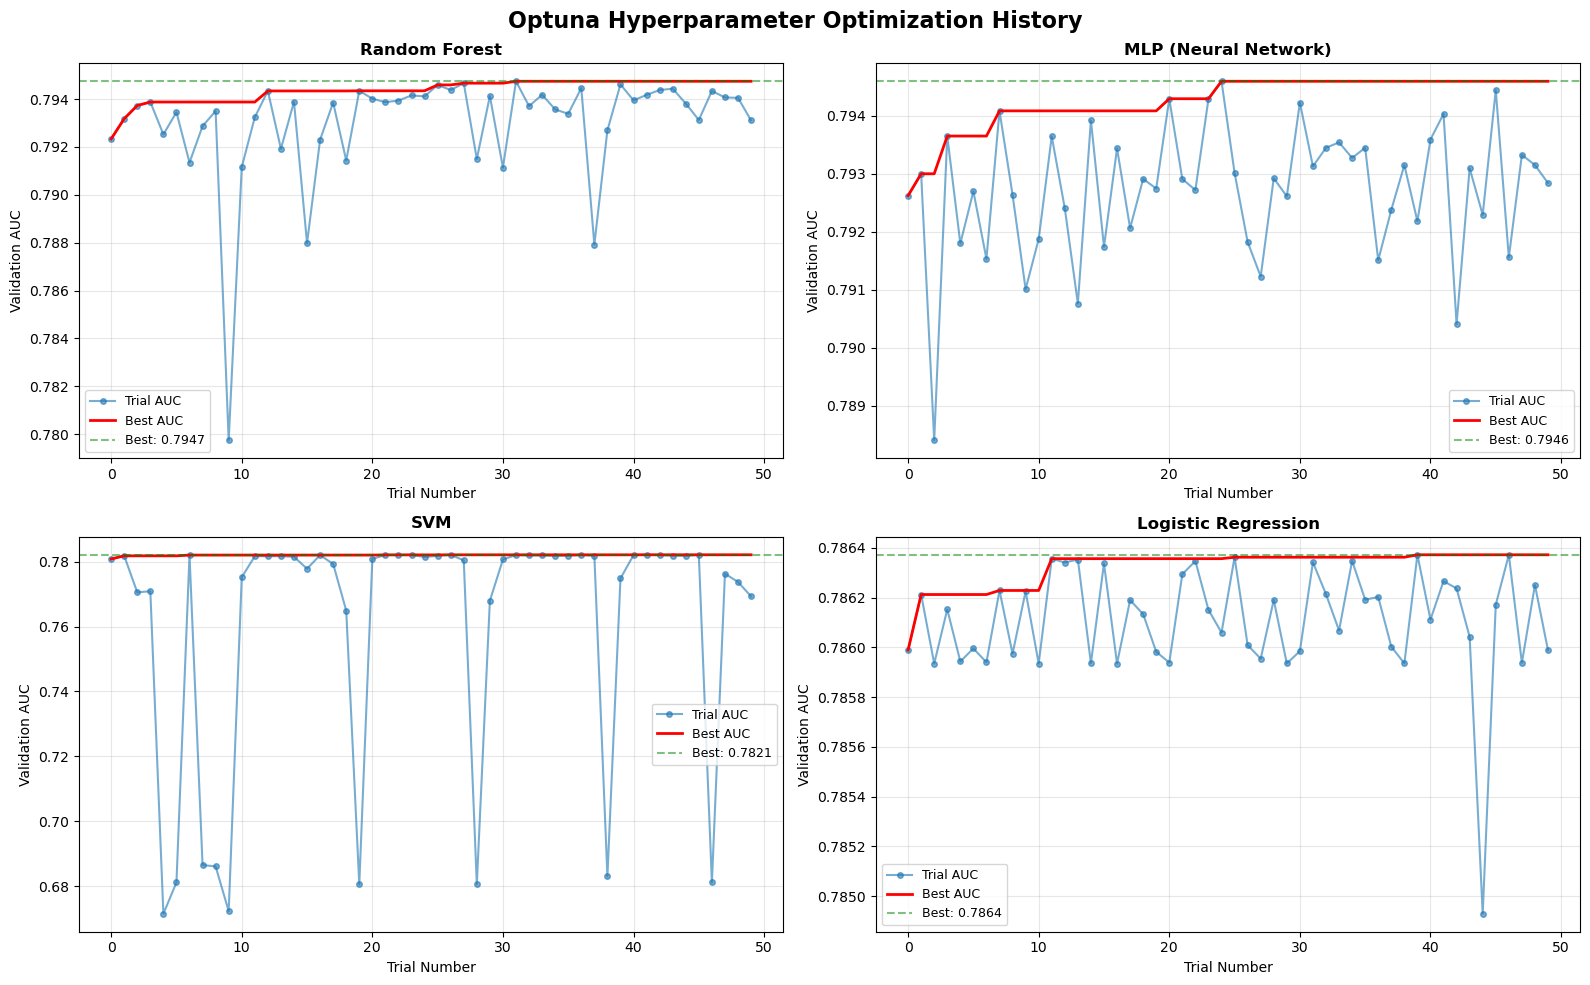

In [29]:
# Visualize Optuna optimization history
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Optuna Hyperparameter Optimization History', fontsize=16, fontweight='bold')

studies = [
    (study_rf, 'Random Forest', axes[0, 0]),
    (study_mlp, 'MLP (Neural Network)', axes[0, 1]),
    (study_svm, 'SVM', axes[1, 0]),
    (study_lr, 'Logistic Regression', axes[1, 1])
]

for study, name, ax in studies:
    # Plot optimization history
    trials = study.trials
    values = [t.value for t in trials]
    best_values = [max(values[:i+1]) for i in range(len(values))]
    
    ax.plot(values, 'o-', alpha=0.6, label='Trial AUC', markersize=4)
    ax.plot(best_values, 'r-', linewidth=2, label='Best AUC')
    ax.axhline(y=study.best_value, color='g', linestyle='--', alpha=0.5, label=f'Best: {study.best_value:.4f}')
    
    ax.set_xlabel('Trial Number', fontsize=10)
    ax.set_ylabel('Validation AUC', fontsize=10)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

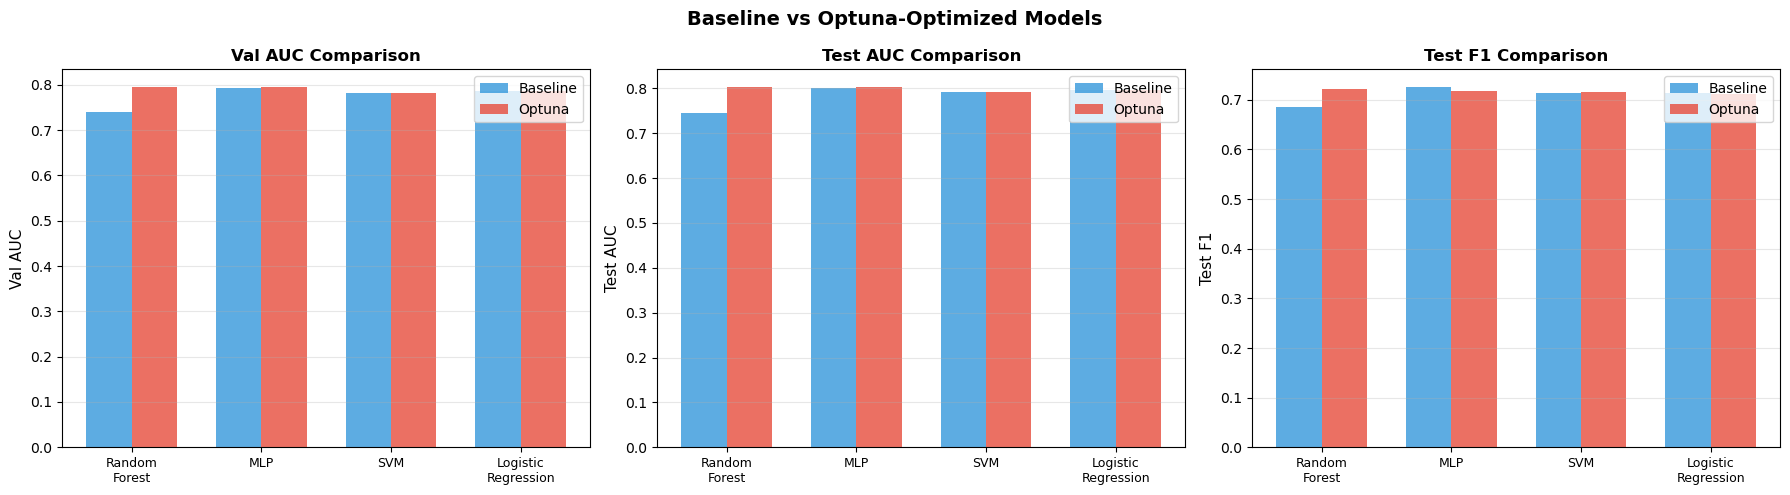

In [30]:
# Compare Baseline vs Optuna-tuned models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Baseline vs Optuna-Optimized Models', fontsize=14, fontweight='bold')

metrics = ['Val AUC', 'Test AUC', 'Test F1']
model_types = ['Random Forest', 'MLP', 'SVM', 'Logistic Regression']

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    
    baseline_scores = []
    optuna_scores = []
    
    for model_type in model_types:
        baseline = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Baseline)"]
        optuna_model = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Optuna)"]  # CHANGED
        
        baseline_scores.append(baseline[metric].values[0] if not baseline.empty else 0)
        optuna_scores.append(optuna_model[metric].values[0] if not optuna_model.empty else 0)  # CHANGED
    
    x = np.arange(len(model_types))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline', color='#3498db', alpha=0.8)
    bars2 = ax.bar(x + width/2, optuna_scores, width, label='Optuna', color='#e74c3c', alpha=0.8)
    
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(' ', '\n') for m in model_types], fontsize=9)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## Choose the Best Model for Explainability

In [31]:
# Select the best performing model
best_model_name = perf_df_rounded.iloc[0]['Model']
best_model_auc = perf_df_rounded.iloc[0]['Test AUC']
best_model_acc = perf_df_rounded.iloc[0]['Test acc']  # Changed: 'Test Acc' → 'Test acc'
best_model_f1 = perf_df_rounded.iloc[0]['Test F1']

print("="*70)
print("BEST MODEL SELECTED")
print("="*70)
print(f"\n🏆 Model: {best_model_name}")
print(f"\n📊 Performance Metrics:")
print(f"   • Test AUC: {best_model_auc:.4f}")
print(f"   • Test Accuracy: {best_model_acc:.4f} ({best_model_acc*100:.2f}%)")
print(f"   • Test F1-Score: {best_model_f1:.4f}")

# Set as proposed model for explainability
proposed = models[best_model_name]
proposed_name = best_model_name
print(f"\n✅ '{proposed_name}' will be used for downstream explainability analysis")

BEST MODEL SELECTED

🏆 Model: Random Forest (Optuna)

📊 Performance Metrics:
   • Test AUC: 0.8021
   • Test Accuracy: 0.7375 (73.75%)
   • Test F1-Score: 0.7212

✅ 'Random Forest (Optuna)' will be used for downstream explainability analysis



OPTUNA IMPROVEMENTS (vs Baseline)
📈 Random Forest: 0.7454 → 0.8021 (+0.0567)
📈 MLP: 0.7999 → 0.8018 (+0.0019)
📈 SVM: 0.7906 → 0.7917 (+0.0011)
📉 Logistic Regression: 0.7964 → 0.7963 (-0.0001)


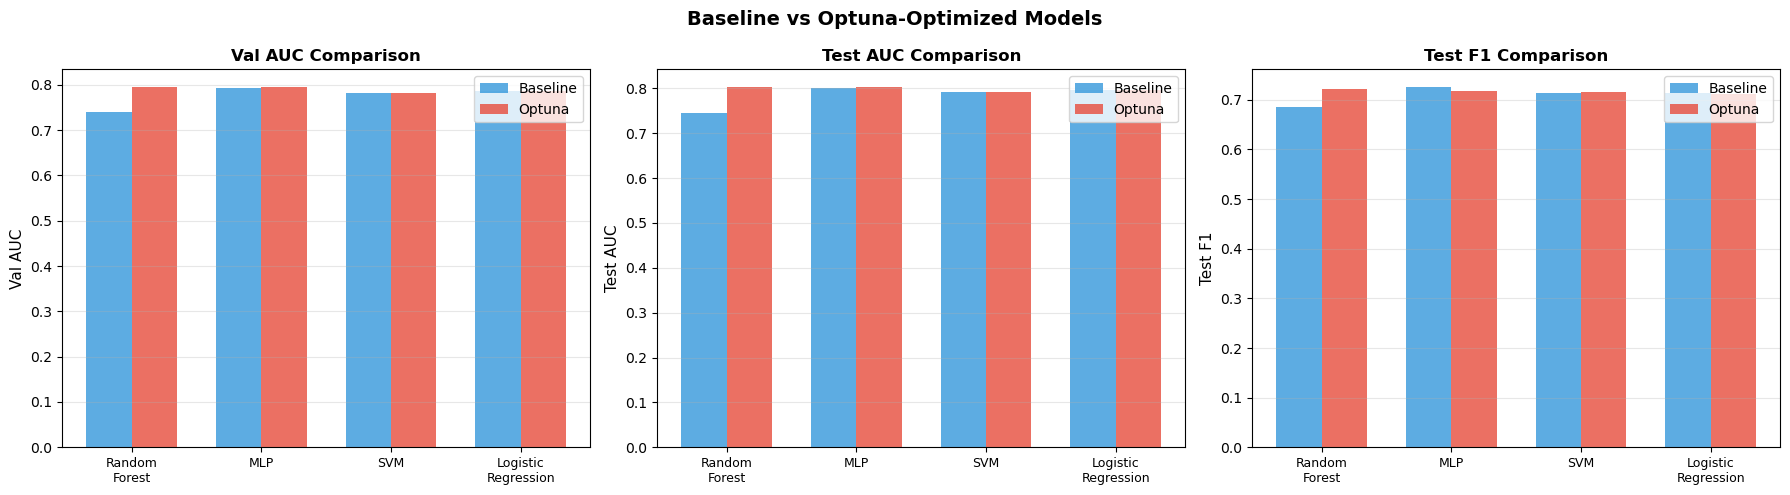

BEST MODEL SELECTED

🏆 Model: Random Forest (Optuna)

📊 Performance Metrics:
   • Test AUC: 0.8021
   • Test Accuracy: 0.7375 (73.75%)
   • Test F1-Score: 0.7212

✅ 'Random Forest (Optuna)' will be used for downstream explainability analysis


In [33]:
# ============================================================================
# OPTUNA IMPROVEMENTS (vs Baseline) - FIXED
# ============================================================================
print("\n" + "="*80)
print("OPTUNA IMPROVEMENTS (vs Baseline)")
print("="*80)

for model_type in ['Random Forest', 'MLP', 'SVM', 'Logistic Regression']:
    baseline = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Baseline)"]
    optuna_model = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Optuna)"]  # FIXED: Don't use 'optuna' as variable name!
    
    if not baseline.empty and not optuna_model.empty:
        baseline_auc = baseline['Test AUC'].values[0]
        optuna_auc = optuna_model['Test AUC'].values[0]
        improvement = optuna_auc - baseline_auc
        
        symbol = "📈" if improvement > 0 else "📉"
        print(f"{symbol} {model_type}: {baseline_auc:.4f} → {optuna_auc:.4f} ({improvement:+.4f})")

# ============================================================================
# PLOTTING COMPARISON - FIXED
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Baseline vs Optuna-Optimized Models', fontsize=14, fontweight='bold')

metrics = ['Val AUC', 'Test AUC', 'Test F1']
model_types = ['Random Forest', 'MLP', 'SVM', 'Logistic Regression']

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    
    baseline_scores = []
    optuna_scores = []
    
    for model_type in model_types:
        baseline = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Baseline)"]
        optuna_model = perf_df_rounded[perf_df_rounded['Model'] == f"{model_type} (Optuna)"]  # FIXED
        
        baseline_scores.append(baseline[metric].values[0] if not baseline.empty else 0)
        optuna_scores.append(optuna_model[metric].values[0] if not optuna_model.empty else 0)  # FIXED
    
    x = np.arange(len(model_types))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline', color='#3498db', alpha=0.8)
    bars2 = ax.bar(x + width/2, optuna_scores, width, label='Optuna', color='#e74c3c', alpha=0.8)
    
    ax.set_ylabel(metric, fontsize=11)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(' ', '\n') for m in model_types], fontsize=9)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# SELECT BEST MODEL - FIXED
# ============================================================================
best_model_name = perf_df_rounded.iloc[0]['Model']
best_model_auc = perf_df_rounded.iloc[0]['Test AUC']
best_model_acc = perf_df_rounded.iloc[0]['Test acc']  # FIXED: lowercase 'acc'
best_model_f1 = perf_df_rounded.iloc[0]['Test F1']

print("="*70)
print("BEST MODEL SELECTED")
print("="*70)
print(f"\n🏆 Model: {best_model_name}")
print(f"\n📊 Performance Metrics:")
print(f"   • Test AUC: {best_model_auc:.4f}")
print(f"   • Test Accuracy: {best_model_acc:.4f} ({best_model_acc*100:.2f}%)")
print(f"   • Test F1-Score: {best_model_f1:.4f}")

# Set as proposed model for explainability
proposed = models[best_model_name]
proposed_name = best_model_name
print(f"\n✅ '{proposed_name}' will be used for downstream explainability analysis")

In [35]:
# ============================================================================
# FIX: Re-import optuna to clear variable shadowing
# ============================================================================
import optuna
from optuna.samplers import TPESampler

print("✅ Optuna library re-imported successfully")
print(f"Type check: {type(optuna)}")  # Should show: <class 'module'>

✅ Optuna library re-imported successfully
Type check: <class 'module'>


In [36]:
# Hyperparameter Tuning for Logistic Regression using Optuna
def objective_lr(trial):
    # Suggest hyperparameters
    C = trial.suggest_float('C', 0.001, 100, log=True)
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2', 'elasticnet'])
    solver = trial.suggest_categorical('solver', ['saga'])  # saga supports all penalties
    
    # For elasticnet, need l1_ratio
    if penalty == 'elasticnet':
        l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    else:
        l1_ratio = None
    
    # Create pipeline
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
            C=C,
            penalty=penalty,
            solver=solver,
            l1_ratio=l1_ratio,
            max_iter=2000,
            random_state=42
        ))
    ])
    
    # Train and evaluate
    model.fit(X_train, y_train)
    y_val_proba = model.predict_proba(X_val)[:, 1]
    auc_score = roc_auc_score(y_val, y_val_proba)
    
    return auc_score

# Run optimization
print("Optimizing Logistic Regression...")
study_lr = optuna.create_study(direction='maximize', sampler=TPESampler(seed=42))
study_lr.optimize(objective_lr, n_trials=50, show_progress_bar=True)

print(f"\nBest AUC: {study_lr.best_value:.4f}")
print(f"Best parameters: {study_lr.best_params}")

Optimizing Logistic Regression...


  0%|          | 0/50 [00:00<?, ?it/s]


Best AUC: 0.7864
Best parameters: {'C': 0.0010036099541173098, 'penalty': 'l2', 'solver': 'saga'}


In [37]:
# Build all models (both baseline and Optuna-tuned)
models = {}

# Baseline models (no tuning)
models["Decision Tree (Baseline)"] = DecisionTreeClassifier(random_state=42)
models["Naive Bayes (Baseline)"] = GaussianNB()
models["k-NN (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()), 
    ("clf", KNeighborsClassifier(n_neighbors=15))
])

# Optuna-tuned models
# Random Forest (Optuna)
rf_params = study_rf.best_params
models["Random Forest (Optuna)"] = RandomForestClassifier(
    n_estimators=rf_params['n_estimators'],
    max_depth=rf_params['max_depth'],
    min_samples_split=rf_params['min_samples_split'],
    min_samples_leaf=rf_params['min_samples_leaf'],
    max_features=rf_params['max_features'],
    random_state=42,
    n_jobs=-1
)

# Baseline RF for comparison
models["Random Forest (Baseline)"] = RandomForestClassifier(
    n_estimators=400, 
    random_state=42, 
    n_jobs=-1
)

# MLP (Optuna)
mlp_params = study_mlp.best_params
n_layers = mlp_params['n_layers']
hidden_sizes = tuple([mlp_params[f'n_units_l{i}'] for i in range(n_layers)])

models["MLP (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', MLPClassifier(
        hidden_layer_sizes=hidden_sizes,
        alpha=mlp_params['alpha'],
        learning_rate_init=mlp_params['learning_rate_init'],
        activation=mlp_params['activation'],
        max_iter=1000,
        random_state=42,
        early_stopping=True,
        n_iter_no_change=10
    ))
])

# Baseline MLP
models["MLP (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42))
])

# SVM (Optuna)
svm_params = study_svm.best_params
models["SVM (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', SVC(
        C=svm_params['C'],
        gamma=svm_params['gamma'],
        kernel=svm_params['kernel'],
        degree=svm_params.get('degree', 3),
        probability=True,
        random_state=42
    ))
])

# Baseline SVM
models["SVM (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="rbf", probability=True, random_state=42))
])

# Logistic Regression (Optuna)
lr_params = study_lr.best_params
models["Logistic Regression (Optuna)"] = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(
        C=lr_params['C'],
        penalty=lr_params['penalty'],
        solver=lr_params['solver'],
        l1_ratio=lr_params.get('l1_ratio', None),
        max_iter=2000,
        random_state=42
    ))
])

# Baseline LR
models["Logistic Regression (Baseline)"] = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000))
])

print(f"Total models: {len(models)}")
for name in models.keys():
    print(f"  - {name}")

Total models: 11
  - Decision Tree (Baseline)
  - Naive Bayes (Baseline)
  - k-NN (Baseline)
  - Random Forest (Optuna)
  - Random Forest (Baseline)
  - MLP (Optuna)
  - MLP (Baseline)
  - SVM (Optuna)
  - SVM (Baseline)
  - Logistic Regression (Optuna)
  - Logistic Regression (Baseline)


In [38]:
# Train and evaluate all models
results = []
for name, m in models.items():
    print(f"Training {name}...")
    m.fit(X_train, y_train)
    results.append(eval_on_val_and_test(name, m, X_val, y_val, X_test, y_test))

perf_df = pd.DataFrame(results).sort_values("Test AUC", ascending=False)
perf_df_rounded = perf_df.copy()
for c in perf_df.columns[1:]:
    perf_df_rounded[c] = perf_df_rounded[c].astype(float).round(3)

print("\n" + "="*80)
print("MODEL PERFORMANCE COMPARISON")
print("="*80)
perf_df_rounded

Training Decision Tree (Baseline)...
Training Naive Bayes (Baseline)...
Training k-NN (Baseline)...
Training Random Forest (Optuna)...
Training Random Forest (Baseline)...
Training MLP (Optuna)...
Training MLP (Baseline)...
Training SVM (Optuna)...
Training SVM (Baseline)...
Training Logistic Regression (Optuna)...
Training Logistic Regression (Baseline)...

MODEL PERFORMANCE COMPARISON


,Model,Val AUC,Val acc,Val F1,Test AUC,Test acc,Test F1
5,MLP (Optuna),0.795,0.725,0.704,0.802,0.738,0.717
3,Random Forest (Optuna),0.795,0.729,0.712,0.801,0.736,0.720
6,MLP (Baseline),0.792,0.727,0.715,0.800,0.736,0.725
10,Logistic Regression (Baseline),0.786,0.723,0.703,0.796,0.734,0.714
9,Logistic Regression (Optuna),0.786,0.723,0.702,0.796,0.733,0.713
7,SVM (Optuna),0.782,0.726,0.703,0.792,0.737,0.716
8,SVM (Baseline),0.781,0.726,0.701,0.791,0.737,0.715
1,Naive Bayes (Baseline),0.778,0.716,0.681,0.786,0.726,0.693
2,k-NN (Baseline),0.774,0.718,0.706,0.780,0.726,0.714
4,Random Forest (Baseline),0.740,0.682,0.682,0.745,0.687,0.686


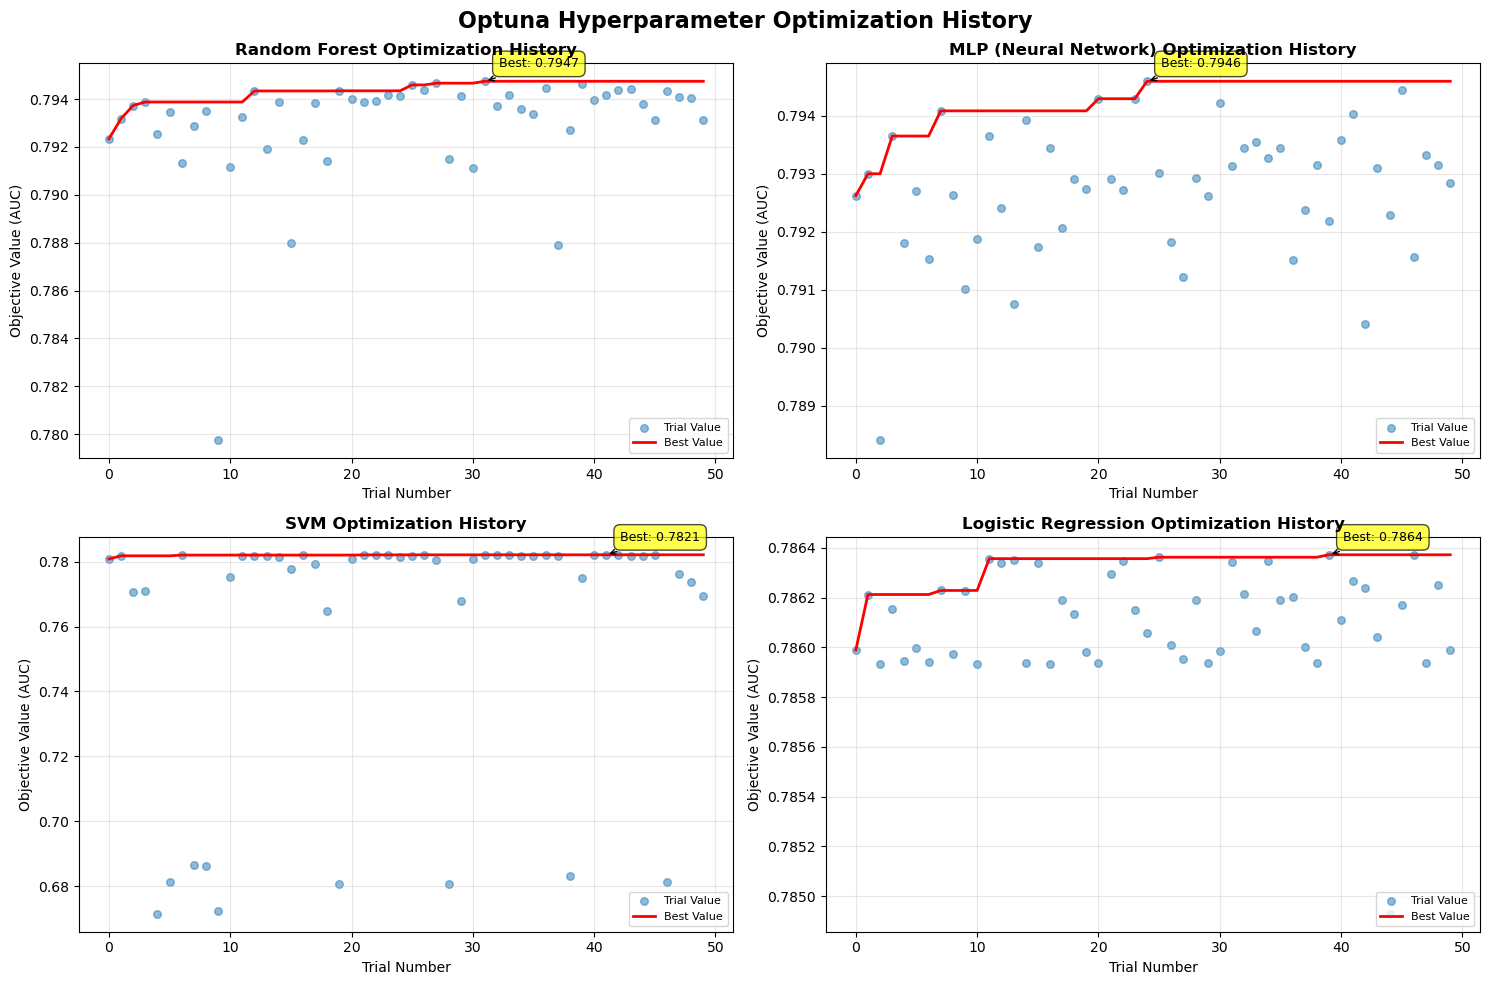

In [40]:
# Fixed Optuna Visualization Code
import matplotlib.pyplot as plt
import numpy as np

# Create subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Optuna Hyperparameter Optimization History', fontsize=16, fontweight='bold')

studies = [
    (study_rf, 'Random Forest', axes[0, 0]),
    (study_mlp, 'MLP (Neural Network)', axes[0, 1]),
    (study_svm, 'SVM', axes[1, 0]),
    (study_lr, 'Logistic Regression', axes[1, 1])
]

for study, name, ax in studies:
    # Extract trial data manually
    trials = study.trials
    trial_numbers = [t.number for t in trials]
    values = [t.value for t in trials if t.value is not None]
    
    # Calculate best value seen so far at each trial
    best_values = []
    current_best = float('-inf')  # Assuming maximization
    for val in values:
        current_best = max(current_best, val)
        best_values.append(current_best)
    
    # Plot individual trial values
    ax.scatter(trial_numbers[:len(values)], values, alpha=0.5, s=30, label='Trial Value')
    
    # Plot best value curve
    ax.plot(trial_numbers[:len(best_values)], best_values, 
            color='red', linewidth=2, label='Best Value')
    
    # Formatting
    ax.set_xlabel('Trial Number', fontsize=10)
    ax.set_ylabel('Objective Value (AUC)', fontsize=10)
    ax.set_title(f'{name} Optimization History', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)
    
    # Add best value annotation
    if values:
        best_idx = np.argmax(values)
        ax.annotate(f'Best: {max(values):.4f}', 
                    xy=(trial_numbers[best_idx], max(values)),
                    xytext=(10, 10), textcoords='offset points',
                    fontsize=9, ha='left',
                    bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.7),
                    arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0'))

plt.tight_layout()
plt.show()

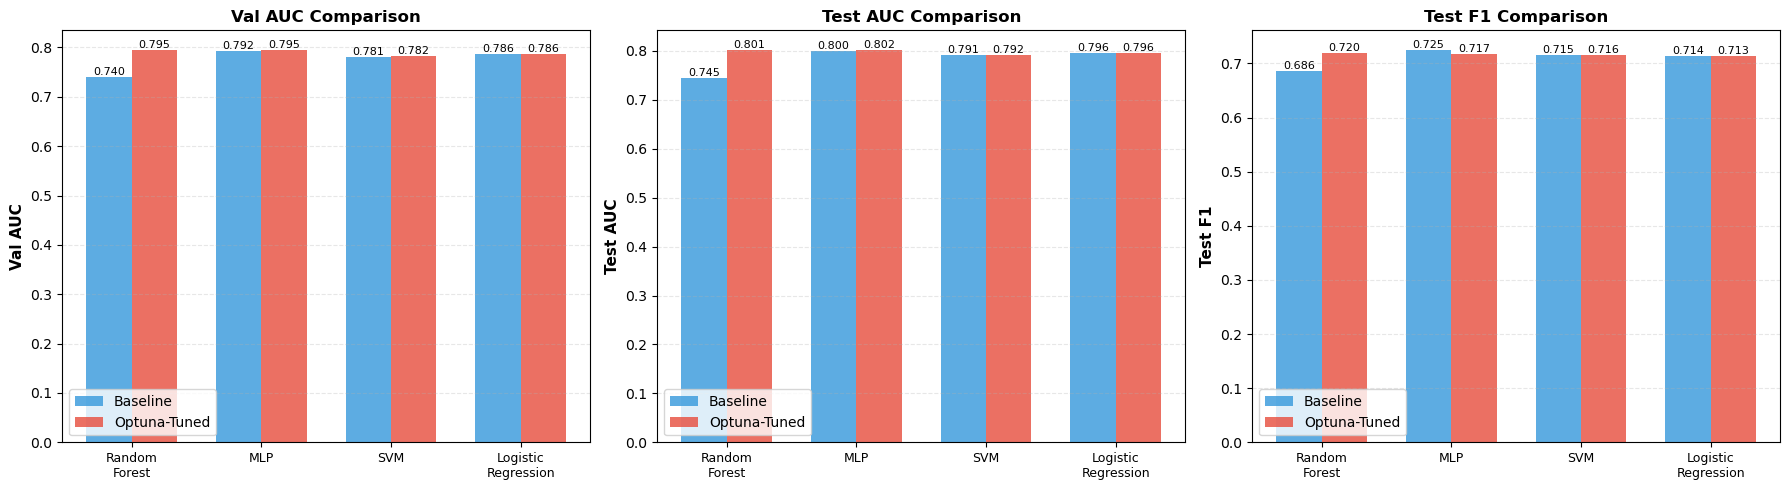

In [41]:
# Create comparison between baseline and Optuna-tuned models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

metrics = ['Val AUC', 'Test AUC', 'Test F1']
colors = ['#3498db', '#e74c3c']  # Blue for baseline, Red for Optuna

for idx, metric in enumerate(metrics):
    ax = axes[idx]
    
    # Get data for each model type
    model_types = ['Random Forest', 'MLP', 'SVM', 'Logistic Regression']
    baseline_scores = []
    optuna_scores = []
    
    for model_type in model_types:
        baseline_name = f"{model_type} (Baseline)"
        optuna_name = f"{model_type} (Optuna)"
        
        baseline_row = perf_df_rounded[perf_df_rounded['Model'] == baseline_name]
        optuna_row = perf_df_rounded[perf_df_rounded['Model'] == optuna_name]
        
        if not baseline_row.empty:
            baseline_scores.append(baseline_row[metric].values[0])
        else:
            baseline_scores.append(0)
            
        if not optuna_row.empty:
            optuna_scores.append(optuna_row[metric].values[0])
        else:
            optuna_scores.append(0)
    
    x = np.arange(len(model_types))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, baseline_scores, width, label='Baseline', color=colors[0], alpha=0.8)
    bars2 = ax.bar(x + width/2, optuna_scores, width, label='Optuna-Tuned', color=colors[1], alpha=0.8)
    
    ax.set_ylabel(metric, fontsize=11, fontweight='bold')
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(' ', '\n') for m in model_types], fontsize=9)
    ax.legend()
    ax.grid(axis='y', alpha=0.3, linestyle='--')
    
    # Add value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

9) Choose the main model for explainability

In [43]:
# First, let's check what columns are available
print("Available columns in perf_df_rounded:")
print(perf_df_rounded.columns.tolist())
print("\n" + "="*80)

# Choose the best performing model
best_model_name = perf_df_rounded.iloc[0]['Model']
print(f"Best performing model: {best_model_name}")

# Print all available metrics (robust approach)
print("\nPerformance Metrics:")
for col in perf_df_rounded.columns:
    if col != 'Model':
        print(f"{col}: {perf_df_rounded.iloc[0][col]}")

# Set as proposed model
proposed = models[best_model_name]
proposed_name = best_model_name

# Also keep MLP (Optuna) as an alternative if it's not the best
if "MLP (Optuna)" in models:
    mlp_proposed = models["MLP (Optuna)"]
else:
    mlp_proposed = models["MLP (Baseline)"]

print(f"\nProposed model set to: {proposed_name}")

Available columns in perf_df_rounded:
['Model', 'Val AUC', 'Val acc', 'Val F1', 'Test AUC', 'Test acc', 'Test F1']

Best performing model: MLP (Optuna)

Performance Metrics:
Val AUC: 0.795
Val acc: 0.725
Val F1: 0.704
Test AUC: 0.802
Test acc: 0.738
Test F1: 0.717

Proposed model set to: MLP (Optuna)


In [44]:
# Choose the best performing model
best_model_name = perf_df_rounded.iloc[0]['Model']
print(f"Best performing model: {best_model_name}")
print(f"Test AUC: {perf_df_rounded.iloc[0]['Test AUC']}")

# Try different possible column names for accuracy
if 'Test Acc' in perf_df_rounded.columns:
    print(f"Test Accuracy: {perf_df_rounded.iloc[0]['Test Acc']}")
elif 'Test Accuracy' in perf_df_rounded.columns:
    print(f"Test Accuracy: {perf_df_rounded.iloc[0]['Test Accuracy']}")
elif 'Accuracy' in perf_df_rounded.columns:
    print(f"Test Accuracy: {perf_df_rounded.iloc[0]['Accuracy']}")

# Try different possible column names for F1
if 'Test F1' in perf_df_rounded.columns:
    print(f"Test F1: {perf_df_rounded.iloc[0]['Test F1']}")
elif 'F1 Score' in perf_df_rounded.columns:
    print(f"Test F1: {perf_df_rounded.iloc[0]['F1 Score']}")
elif 'F1' in perf_df_rounded.columns:
    print(f"Test F1: {perf_df_rounded.iloc[0]['F1']}")

# Set as proposed model
proposed = models[best_model_name]
proposed_name = best_model_name

# Also keep MLP (Optuna) as an alternative if it's not the best
if "MLP (Optuna)" in models:
    mlp_proposed = models["MLP (Optuna)"]
else:
    mlp_proposed = models["MLP (Baseline)"]

print(f"\nProposed model set to: {proposed_name}")

Best performing model: MLP (Optuna)
Test AUC: 0.802
Test F1: 0.717

Proposed model set to: MLP (Optuna)


In [45]:
# Choose the best performing model
best_model_name = perf_df_rounded.iloc[0]['Model']

print(f"Best performing model: {best_model_name}")
print("\nPerformance Metrics:")
print(perf_df_rounded.iloc[0].to_string())

# Set as proposed model
proposed = models[best_model_name]
proposed_name = best_model_name

# Also keep MLP (Optuna) as an alternative if it's not the best
if "MLP (Optuna)" in models:
    mlp_proposed = models["MLP (Optuna)"]
else:
    mlp_proposed = models["MLP (Baseline)"]

print(f"\nProposed model set to: {proposed_name}")

Best performing model: MLP (Optuna)

Performance Metrics:
Model       MLP (Optuna)
Val AUC            0.795
Val acc            0.725
Val F1             0.704
Test AUC           0.802
Test acc           0.738
Test F1            0.717

Proposed model set to: MLP (Optuna)


Make a comparison table (for the paper)

In [46]:
# The 'perf_df_rounded' DataFrame is already computed in the previous cell (269YnDIscL01)
# and contains the evaluation metrics for all baseline models, including the MLP (sklearn).
# So, we can directly print it here.

print(perf_df_rounded)
# The line `df.round(3)` was a leftover and is not needed.

                             Model  Val AUC  Val acc  Val F1  Test AUC  \
5                     MLP (Optuna)    0.795    0.725   0.704     0.802   
3           Random Forest (Optuna)    0.795    0.729   0.712     0.801   
6                   MLP (Baseline)    0.792    0.727   0.715     0.800   
10  Logistic Regression (Baseline)    0.786    0.723   0.703     0.796   
9     Logistic Regression (Optuna)    0.786    0.723   0.702     0.796   
7                     SVM (Optuna)    0.782    0.726   0.703     0.792   
8                   SVM (Baseline)    0.781    0.726   0.701     0.791   
1           Naive Bayes (Baseline)    0.778    0.716   0.681     0.786   
2                  k-NN (Baseline)    0.774    0.718   0.706     0.780   
4         Random Forest (Baseline)    0.740    0.682   0.682     0.745   
0         Decision Tree (Baseline)    0.638    0.638   0.629     0.648   

    Test acc  Test F1  
5      0.738    0.717  
3      0.736    0.720  
6      0.736    0.725  
10     0.734   

# 10. Final evaluation on test set

Confusion matrices (train + test)

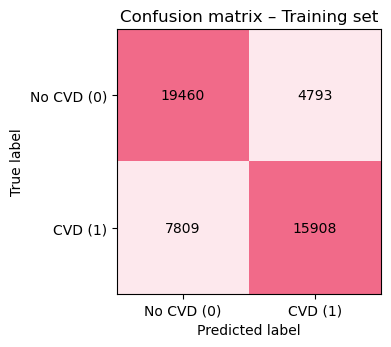

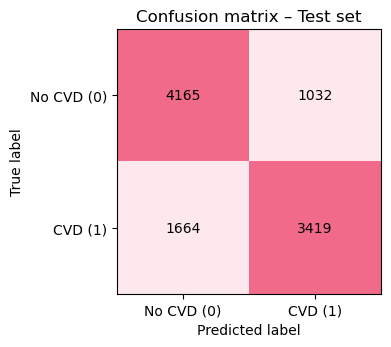

In [47]:
from matplotlib.colors import ListedColormap

# Custom 2-colour colormap for CM, if you like
cm_colors = ListedColormap(["#FDE8ED", "#F16A89"])

# Calculate predictions for the proposed model
y_train_pred = proposed.predict(X_train)
y_test_proba = proposed.predict_proba(X_test)[:, 1]
y_test_pred  = proposed.predict(X_test)

# TRAIN CM
cm_train = confusion_matrix(y_train, y_train_pred)
disp_train = ConfusionMatrixDisplay(cm_train, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_train.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_train.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Training set")
plt.tight_layout()
plt.show()

# TEST CM
cm_test = confusion_matrix(y_test, y_test_pred)
disp_test = ConfusionMatrixDisplay(cm_test, display_labels=["No CVD (0)", "CVD (1)"])

fig, ax = plt.subplots(figsize=(4, 4))
disp_test.plot(cmap=cm_colors, values_format="d", colorbar=False, ax=ax)
for text in disp_test.text_.ravel():
    text.set_color("black")
ax.set_title("Confusion matrix – Test set")
plt.tight_layout()
plt.show()

In [48]:
test_acc = accuracy_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test ROC-AUC : {test_auc:.3f}")

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, digits=3))

Test accuracy: 0.738
Test ROC-AUC : 0.802

Classification report (test):
              precision    recall  f1-score   support

           0      0.715     0.801     0.755      5197
           1      0.768     0.673     0.717      5083

    accuracy                          0.738     10280
   macro avg      0.741     0.737     0.736     10280
weighted avg      0.741     0.738     0.737     10280



ROC curves

findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.
findfont: Font family ' times new Roman' not found.


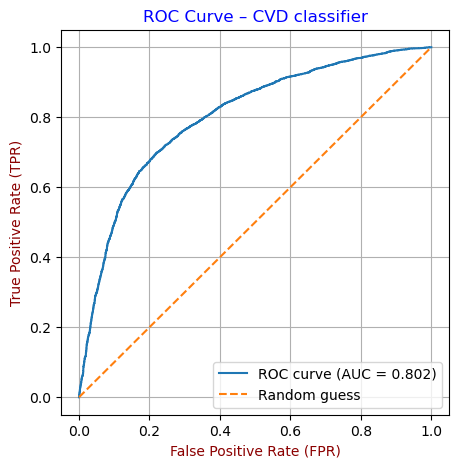

In [49]:
# ROC
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random guess")
font1 = {'family':' times new Roman','color':'blue','size':12}
font2 = {'family':' times new Roman','color':'darkred','size':10}
plt.xlabel("False Positive Rate (FPR)",fontdict=font2)
plt.ylabel("True Positive Rate (TPR)",fontdict=font2)
plt.title("ROC Curve – CVD classifier",fontdict=font1)
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

Precision–Recall curve

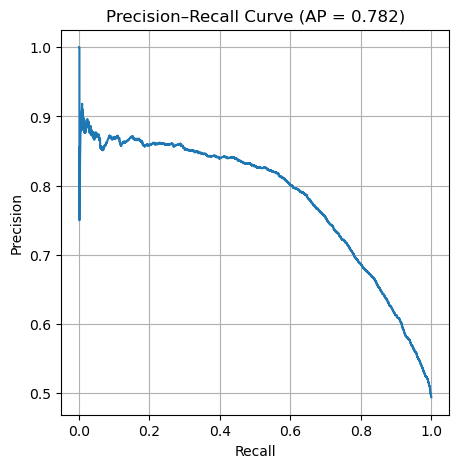

In [50]:
precision, recall, _ = precision_recall_curve(y_test, y_test_proba)
ap = average_precision_score(y_test, y_test_proba)

plt.figure(figsize=(5, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (AP = {ap:.3f})")
plt.grid(True)
plt.show()

11. Global explainability (Permutation importance + PDP)

Age            0.032048
Cholesterol    0.028503
SBP            0.025016
PP             0.022239
MAP            0.021167
DBP            0.008307
BMI            0.004355
risk_count     0.003666
active         0.003625
Gender         0.001170
Glucose        0.001005
smoking        0.000635
alcohol        0.000433
dtype: float64


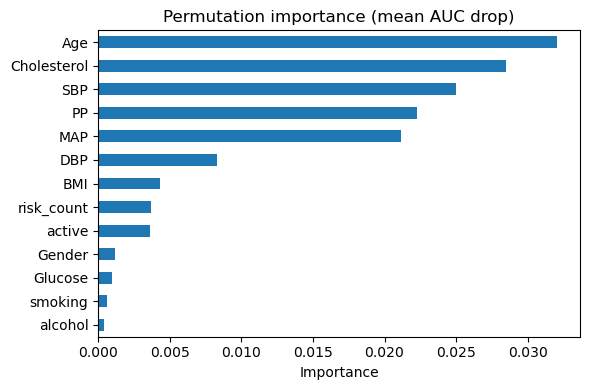

In [51]:
# Permutation importance
result_perm = permutation_importance(
    proposed,
    X_test,
    y_test,
    n_repeats=10,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

perm_importance = pd.Series(
    result_perm.importances_mean,
    index=feature_cols
).sort_values(ascending=False)

print(perm_importance)

plt.figure(figsize=(6, 4))
perm_importance.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Permutation importance (mean AUC drop)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

Partial dependence plots for key features

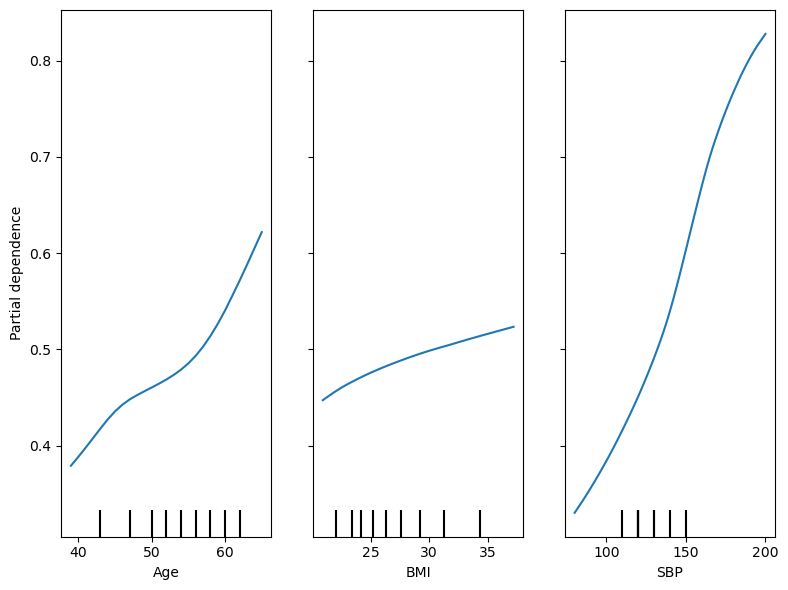

In [52]:
features_to_plot = ["Age", "BMI", "SBP"]

fig, ax = plt.subplots(figsize=(8, 6))
PartialDependenceDisplay.from_estimator(
    proposed,
    X_train,
    features_to_plot,
    kind="average",
    ax=ax
)
plt.tight_layout()
plt.show()

# A) Transfer Learning (Pretrain → Fine-tune) with PyTorch

11) Prepare scaled tensors

In [53]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_sc, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32)

X_val_t   = torch.tensor(X_val_sc, dtype=torch.float32)
y_val_t   = torch.tensor(y_val.values, dtype=torch.float32)

X_test_t  = torch.tensor(X_test_sc, dtype=torch.float32)
y_test_t  = torch.tensor(y_test.values, dtype=torch.float32)

n_features = X_train_t.shape[1]
print("n_features:", n_features)

n_features: 13


12) Define models: Autoencoder (pretrain) + Classifier (fine-tune)

In [54]:
class Encoder(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )
    def forward(self, x):
        return self.net(x)

class AutoEncoder(nn.Module):
    def __init__(self, d_in):
        super().__init__()
        self.encoder = Encoder(d_in)
        self.decoder = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, d_in)
        )
    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat

class Classifier(nn.Module):
    def __init__(self, d_in, encoder=None):
        super().__init__()
        self.encoder = encoder if encoder is not None else Encoder(d_in)
        self.head = nn.Sequential(
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)  # logits
        )
    def forward(self, x):
        z = self.encoder(x)
        logits = self.head(z).squeeze(1)
        return logits

13) Pretrain autoencoder (self-supervised transfer)

In [55]:
device = "cuda" if torch.cuda.is_available() else "cpu"
ae = AutoEncoder(n_features).to(device)

opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
loss_fn = nn.MSELoss()

X_tr = X_train_t.to(device)

ae.train()
for epoch in range(30):
    opt.zero_grad()
    x_hat = ae(X_tr)
    loss = loss_fn(x_hat, X_tr)
    loss.backward()
    opt.step()
    if (epoch+1) % 10 == 0:
        print(f"AE epoch {epoch+1:02d} | recon loss = {loss.item():.4f}")

AE epoch 10 | recon loss = 0.9732
AE epoch 20 | recon loss = 0.9034
AE epoch 30 | recon loss = 0.7810


14) Fine-tune classifier using pretrained encoder

In [56]:
clf = Classifier(n_features, encoder=ae.encoder).to(device)
opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
bce = nn.BCEWithLogitsLoss()

def eval_torch(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X.to(device))
        proba  = torch.sigmoid(logits).cpu().numpy()
        pred   = (proba >= 0.5).astype(int)
    y_np = y.cpu().numpy().astype(int)
    return (
        roc_auc_score(y_np, proba),
        accuracy_score(y_np, pred),
        f1_score(y_np, pred)
    )

clf.train()
for epoch in range(30):
    opt.zero_grad()
    logits = clf(X_train_t.to(device))
    loss = bce(logits, y_train_t.to(device))
    loss.backward()
    opt.step()

    if (epoch+1) % 10 == 0:
        val_auc, val_acc, val_f1 = eval_torch(clf, X_val_t, y_val_t)
        print(f"CLF epoch {epoch+1:02d} | loss={loss.item():.4f} | val_auc={val_auc:.3f} val_acc={val_acc:.3f} val_f1={val_f1:.3f}")

CLF epoch 10 | loss=0.6776 | val_auc=0.757 val_acc=0.513 val_f1=0.038
CLF epoch 20 | loss=0.6540 | val_auc=0.767 val_acc=0.655 val_f1=0.538
CLF epoch 30 | loss=0.6219 | val_auc=0.774 val_acc=0.708 val_f1=0.659


15) Test performance (Transfer model)

In [57]:
test_auc_t, test_acc_t, test_f1_t = eval_torch(clf, X_test_t, y_test_t)
print("Transfer-learning (AE→MLP) TEST:",
      f"AUC={test_auc_t:.3f}, Acc={test_acc_t:.3f}, F1={test_f1_t:.3f}")

Transfer-learning (AE→MLP) TEST: AUC=0.784, Acc=0.714, F1=0.666


# B) Federated Learning (FedAvg) simulation with PyTorch

16) Create “clients” from training set

In [58]:
def split_clients(X, y, n_clients=5):
    idx = np.arange(len(X))
    np.random.RandomState(42).shuffle(idx)
    splits = np.array_split(idx, n_clients)
    clients = []
    for s in splits:
        clients.append((X[s], y[s]))
    return clients

clients = split_clients(X_train_t, y_train_t, n_clients=5)
print("Clients:", [len(c[0]) for c in clients])

Clients: [9594, 9594, 9594, 9594, 9594]


17) FedAvg training loop

In [59]:
def get_model():
    # fresh model for FL (same architecture as classifier)
    return Classifier(n_features).to(device)

def local_train(model, Xc, yc, epochs=2, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()
    Xc = Xc.to(device)
    yc = yc.to(device)
    for _ in range(epochs):
        opt.zero_grad()
        logits = model(Xc)
        loss = loss_fn(logits, yc)
        loss.backward()
        opt.step()
    return model.state_dict()

def fedavg(state_dicts):
    # average weights
    avg = {}
    for k in state_dicts[0].keys():
        avg[k] = sum(sd[k] for sd in state_dicts) / len(state_dicts)
    return avg

global_model = get_model()

rounds = 20
for r in range(rounds):
    local_states = []
    for (Xc, yc) in clients:
        # start from global weights
        local_model = get_model()
        local_model.load_state_dict(global_model.state_dict())

        sd = local_train(local_model, Xc, yc, epochs=2, lr=1e-3)
        local_states.append(sd)

    global_sd = fedavg(local_states)
    global_model.load_state_dict(global_sd)

    if (r+1) % 5 == 0:
        val_auc, val_acc, val_f1 = eval_torch(global_model, X_val_t, y_val_t)
        print(f"Round {r+1:02d} | val_auc={val_auc:.3f}, val_acc={val_acc:.3f}, val_f1={val_f1:.3f}")

Round 05 | val_auc=0.766, val_acc=0.494, val_f1=0.662
Round 10 | val_auc=0.780, val_acc=0.494, val_f1=0.662
Round 15 | val_auc=0.782, val_acc=0.583, val_f1=0.694
Round 20 | val_auc=0.782, val_acc=0.714, val_f1=0.716


18) Federated test performance

In [60]:
test_auc_fl, test_acc_fl, test_f1_fl = eval_torch(global_model, X_test_t, y_test_t)
print("Federated (FedAvg) TEST:",
      f"AUC={test_auc_fl:.3f}, Acc={test_acc_fl:.3f}, F1={test_f1_fl:.3f}")

Federated (FedAvg) TEST: AUC=0.791, Acc=0.729, F1=0.730


19) Integrated Gradients (PyTorch model) – global + single patient

Single patient IG

In [61]:
ig = IntegratedGradients(global_model)

idx = 14
x0 = X_test_t[idx:idx+1].to(device)

global_model.eval()
attr = ig.attribute(x0, target=None)  # binary logit
attr = attr.detach().cpu().numpy().reshape(-1)

ig_single = pd.Series(attr, index=feature_cols).sort_values(key=np.abs, ascending=False)
print(ig_single.head(10))

risk_count     0.298737
smoking       -0.157421
Cholesterol    0.129741
Glucose       -0.117542
Age           -0.085287
SBP           -0.084810
PP            -0.056116
MAP           -0.053678
alcohol        0.019100
DBP           -0.012586
dtype: float32


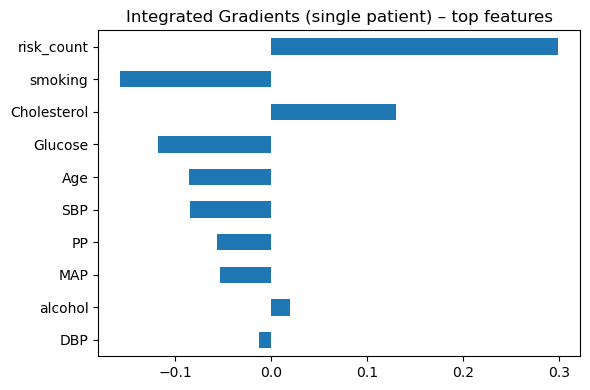

In [62]:
plt.figure(figsize=(6,4))
ig_single.head(10)[::-1].plot(kind="barh")
plt.title("Integrated Gradients (single patient) – top features")
plt.tight_layout()
plt.show()

Global IG (mean |IG| over test set)

In [63]:
all_attr = []
for i in range(len(X_test_t)):
    a = ig.attribute(X_test_t[i:i+1].to(device))
    all_attr.append(a.detach().cpu().numpy().reshape(-1))

all_attr = np.vstack(all_attr)
mean_abs_ig = np.mean(np.abs(all_attr), axis=0)

ig_global = pd.Series(mean_abs_ig, index=feature_cols).sort_values(ascending=False)
print(ig_global)

SBP            0.166438
Cholesterol    0.120644
MAP            0.117819
PP             0.114869
DBP            0.086340
Age            0.065194
Glucose        0.054563
BMI            0.043851
risk_count     0.039986
smoking        0.024484
Gender         0.020615
alcohol        0.019209
active         0.015481
dtype: float32


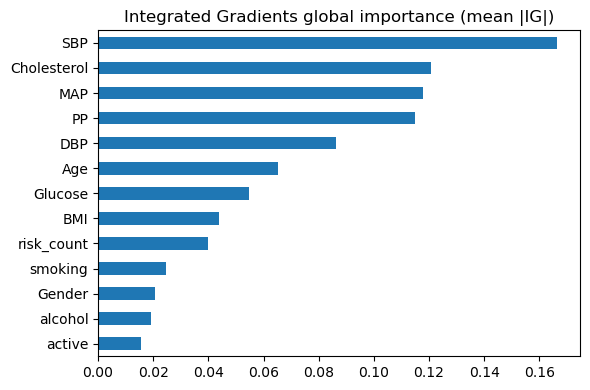

In [64]:
plt.figure(figsize=(6,4))
ig_global[::-1].plot(kind="barh")
plt.title("Integrated Gradients global importance (mean |IG|)")
plt.tight_layout()
plt.show()

20) DiCE counterfactuals (fully working) — using your “proposed” sklearn model

In [65]:
# Prepare Dice data object
dice_df = df[feature_cols + [target_col]].copy()

d = dice_ml.Data(
    dataframe=dice_df,
    continuous_features=["Age","BMI","SBP","DBP","PP","MAP","risk_count"],
    outcome_name=target_col
)

m = dice_ml.Model(model=proposed, backend="sklearn")

dice = Dice(d, m, method="random")   # stable in Colab

In [66]:
# Pick an instance (from test set)
query_instance = X_test.iloc[[0]].copy()
print("Query instance:\n", query_instance)

dice_exp = dice.generate_counterfactuals(
    query_instance,
    total_CFs=3,
    desired_class=0,   # want "No CVD"
    features_to_vary=["SBP","DBP","Cholesterol","Glucose","smoking","alcohol","active","BMI"]
)

dice_exp.visualize_as_dataframe()

Query instance:
        Gender  Age        BMI  SBP  DBP  Cholesterol  Glucose  smoking  \
22535       0   44  33.462225  110   70            1        1        0   

       alcohol  active  PP        MAP  risk_count  
22535        0       1  40  83.333333           0  


100%|██████████| 1/1 [00:00<00:00,  4.40it/s]

Query instance (original outcome : 0)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,0,44,33.462223,110,70,1,1,0,0,1,40,83.333336,0,0



Diverse Counterfactual set (new outcome: 0)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,0,44,33.462225,110,70,1,1,0,0,1,40,83.333333,0,0
1,0,44,33.462225,146,70,1,1,0,0,1,40,83.333333,0,0
2,0,44,33.462225,110,83,1,1,0,0,1,40,83.333333,0,0


## 12. SHAP setup (global & local)

In [68]:
shap.initjs()

# background data for SHAP (from train set)
X_background = X_train.sample(300, random_state=42)

# Explainer for predict_proba
explainer = shap.Explainer(proposed.predict_proba, X_background)
class_idx = 1  # CVD = 1

# Compute SHAP on test data
X_explain = X_test.copy()
shap_values_all = explainer(X_explain)        # shape: (n_samples, 2, n_features)
shap_values_cvd = shap_values_all[..., 1]     # class 1 only

print("shap_values_cvd shape:", shap_values_cvd.values.shape)

PermutationExplainer explainer: 10281it [08:36, 19.51it/s]                           


shap_values_cvd shape: (10280, 13)


# SHAP global plots

Bar plot of mean |SHAP|

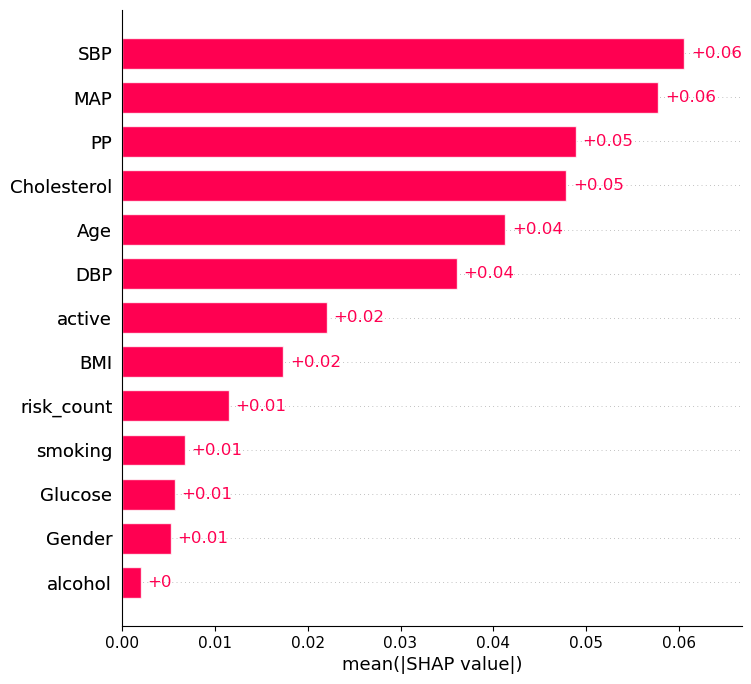

In [69]:
shap.plots.bar(shap_values_cvd, max_display=len(feature_cols))

Beeswarm plot

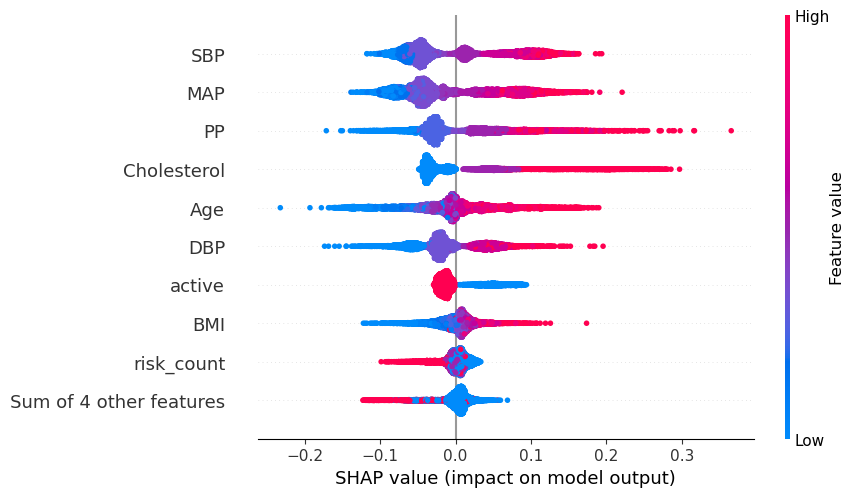

In [70]:
shap.plots.beeswarm(shap_values_cvd)

Dependence plot: BMI

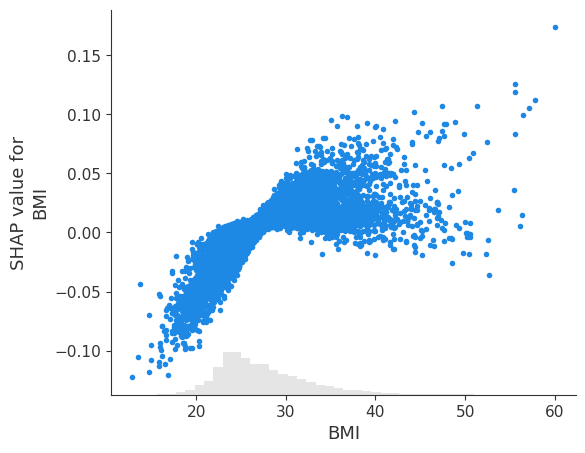

In [71]:
shap.plots.scatter(shap_values_cvd[:, "BMI"])               # SHAP vs BMI

Dependence plot: BMI(culoured)

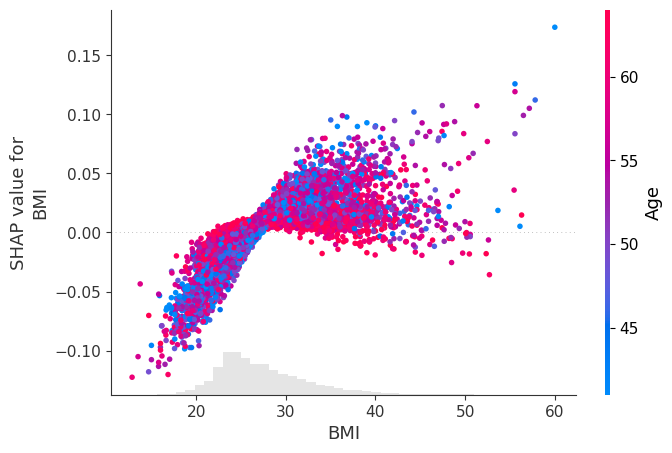

In [72]:
shap.plots.scatter(shap_values_cvd[:, "BMI"],
                   color=shap_values_cvd[:, "Age"])         # coloured by Age

13. SHAP local plots (one example patient)

Example test patient features:
Gender           1.000000
Age             48.000000
BMI             28.577961
SBP            120.000000
DBP             80.000000
Cholesterol      2.000000
Glucose          2.000000
smoking          1.000000
alcohol          0.000000
active           1.000000
PP              40.000000
MAP             93.333333
risk_count       3.000000
Name: 25024, dtype: float64


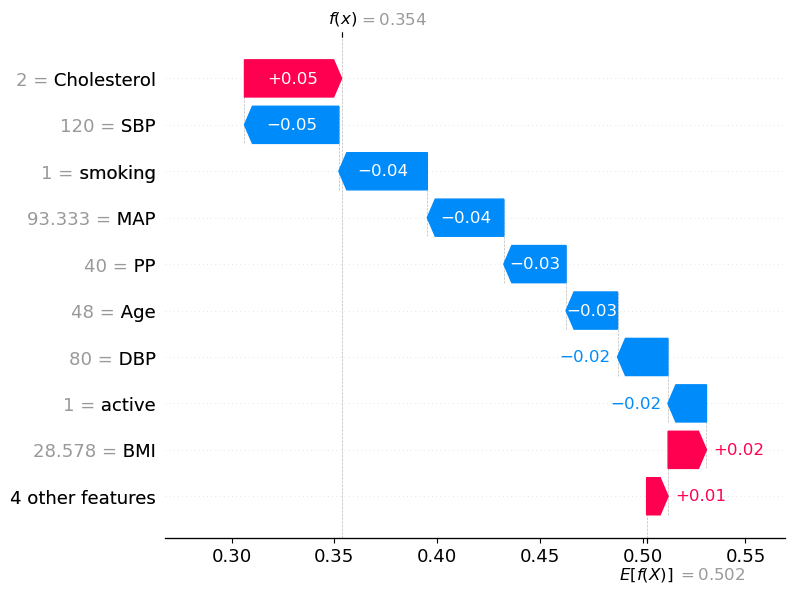

In [73]:
# choose an index from the test set
#idx = 14

print("Example test patient features:")
print(X_test.iloc[idx])

shap.plots.waterfall(shap_values_cvd[idx], max_display=10)

Force plot (static)

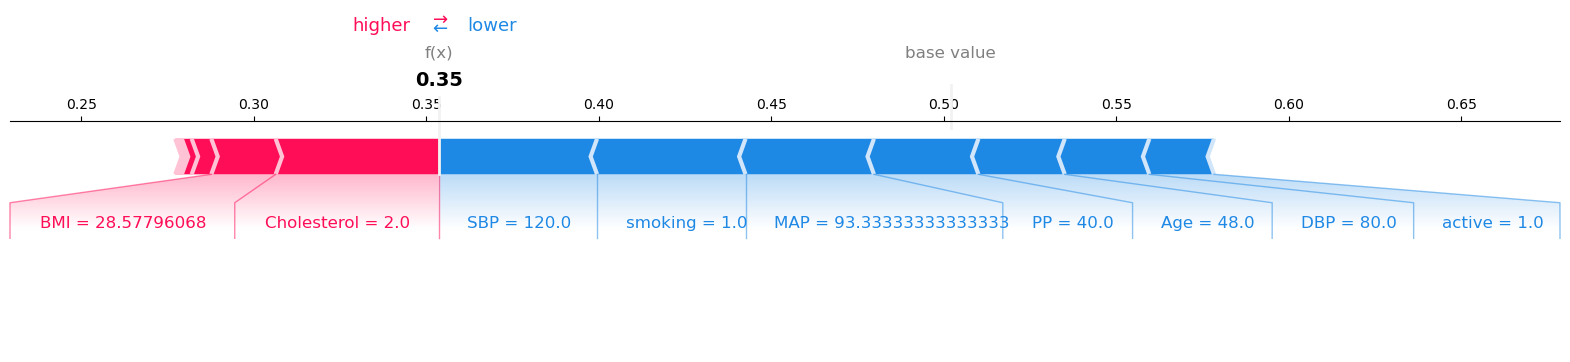

In [74]:
shap.plots.force(shap_values_cvd[idx], matplotlib=True)

14. LIME local explanation (same patient index)

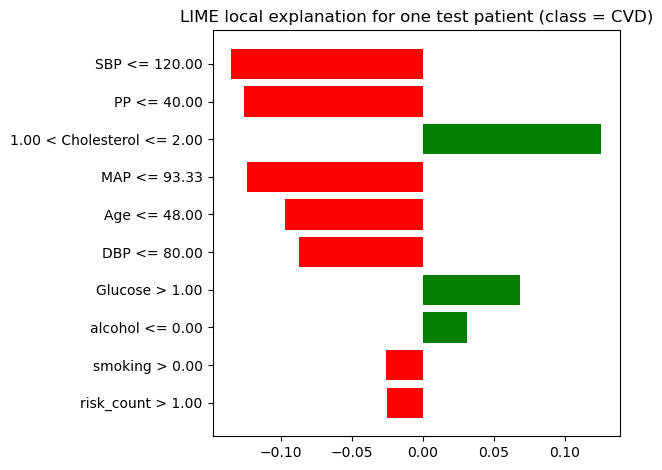

      Feature  Patient value         Feature (condition)  LIME weight
0         SBP     120.000000               SBP <= 120.00    -0.135041
1          PP      40.000000                 PP <= 40.00    -0.126088
2        1.00            NaN  1.00 < Cholesterol <= 2.00     0.125643
3         MAP      93.333333                MAP <= 93.33    -0.123921
4         Age      48.000000                Age <= 48.00    -0.097090
5         DBP      80.000000                DBP <= 80.00    -0.087449
6     Glucose       2.000000              Glucose > 1.00     0.068353
7     alcohol       0.000000             alcohol <= 0.00     0.031315
8     smoking       1.000000              smoking > 0.00    -0.026192
9  risk_count       3.000000           risk_count > 1.00    -0.025577


In [75]:
# Prepare NumPy arrays
X_train_np = X_train.values
X_test_np  = X_test.values

class_names = ["No CVD (0)", "CVD (1)"]

lime_explainer = LimeTabularExplainer(
    training_data = X_train_np,
    feature_names = feature_cols,
    class_names   = class_names,
    mode          = "classification",
    discretize_continuous = True
)

# Explain the same test instance as SHAP (idx)
x_instance = X_test_np[idx]

lime_exp = lime_explainer.explain_instance(
    data_row   = x_instance,
    predict_fn = proposed.predict_proba,
    num_features = 10,
    top_labels   = 2
)

fig = lime_exp.as_pyplot_figure(label=1)
plt.title("LIME local explanation for one test patient (class = CVD)")
plt.tight_layout()
plt.show()

# LIME table
lime_list = lime_exp.as_list(label=1)
lime_df = pd.DataFrame(lime_list, columns=["Feature (condition)", "LIME weight"])

patient_series = X_test.iloc[idx]
patient_dict   = patient_series.to_dict()

def extract_feature_name(lime_cond):
    return lime_cond.split()[0]

lime_df["Feature"] = lime_df["Feature (condition)"].apply(extract_feature_name)
lime_df["Patient value"] = lime_df["Feature"].map(patient_dict)

lime_df = lime_df[["Feature", "Patient value", "Feature (condition)", "LIME weight"]]
print(lime_df)

Clustering (K-Means)

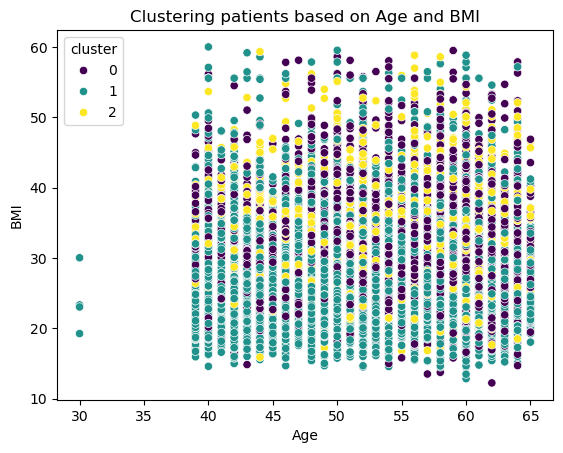

In [76]:
from sklearn.cluster import KMeans

# Select relevant features for clustering
X_clust = X[['Age', 'BMI', 'SBP', 'DBP']]

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
X_clust['cluster'] = kmeans.fit_predict(X_clust)

# Visualize clusters
import seaborn as sns
sns.scatterplot(x=X_clust['Age'], y=X_clust['BMI'], hue=X_clust['cluster'], palette='viridis')
plt.title("Clustering patients based on Age and BMI")
plt.show()


Simple “what-if” / counterfactual curve

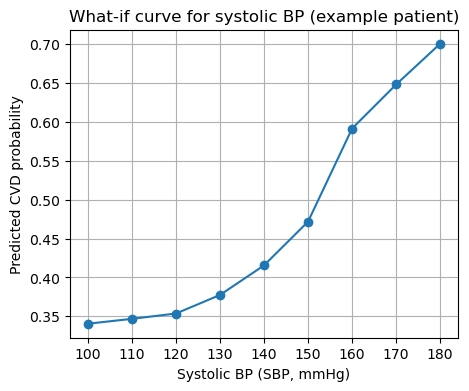

In [77]:
def what_if_curve(example_row, feature, value_grid):
    rows = []
    for v in value_grid:
        r = example_row.copy()
        r[feature] = v
        rows.append(r.iloc[0])
    X_grid = pd.DataFrame(rows)
    proba_grid = proposed.predict_proba(X_grid)[:, 1]
    return value_grid, proba_grid

# Example: what-if curve for systolic BP (SBP)
# Use the same example patient from SHAP/LIME explanation
example_patient_row = X_test.iloc[[idx]] # Use double brackets to keep it a DataFrame

bp_grid = np.arange(100, 181, 10)  # 100, 110, ..., 180
vals, probs = what_if_curve(example_patient_row, "SBP", bp_grid)

plt.figure(figsize=(5, 4))
plt.plot(vals, probs, marker="o")
plt.xlabel("Systolic BP (SBP, mmHg)")
plt.ylabel("Predicted CVD probability")
plt.title("What-if curve for systolic BP (example patient)")
plt.grid(True)
plt.show()

Counterfactual Explanations

In [78]:
import dice_ml
from dice_ml import Dice

# Combine X_train and y_train into a single DataFrame for DiCE
train_df_dice = X_train.copy()
train_df_dice['CVD'] = y_train

# Prepare DiCE model using RandomForest or Neural Network
dice_data = dice_ml.Data(dataframe=train_df_dice, continuous_features=feature_cols, outcome_name='CVD')

# Assuming 'rf_best' is your best Random Forest model from earlier cells
# If you want to use the MLP model, replace 'rf_best' with 'model'
model_dice = dice_ml.Model(model=proposed, backend="sklearn")

# Create DiCE explainer
dice_explainer = Dice(dice_data, model_dice)

# Generate counterfactual for a test patient
# We need to make sure the input to generate_counterfactuals also has all feature_cols
# X_test.iloc[0:1] correctly provides features for one sample
counterfactual = dice_explainer.generate_counterfactuals(X_test.iloc[0:1], total_CFs=3, desired_class="opposite")
counterfactual.visualize_as_dataframe(show_only_changes=True)

100%|██████████| 1/1 [00:00<00:00,  6.44it/s]

Query instance (original outcome : 0)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,0,44,33.462223,110,70,1,1,0,0,1,40,83.333336,0,0



Diverse Counterfactual set (new outcome: 1)


,Gender,Age,BMI,SBP,DBP,Cholesterol,Glucose,smoking,alcohol,active,PP,MAP,risk_count,CVD
0,-,-,-,-,-,-,-,-,-,-,114.0,-,-,1.0
1,-,-,-,-,-,-,-,-,-,-,-,130.253262,-,1.0
2,-,-,-,-,-,-,-,-,-,-,90.0,-,-,1.0


15. Fairness metrics by gender

In [79]:
def group_metrics(group_value, group_name):
    mask = X_test["Gender"] == group_value

    y_true_g  = y_test[mask]
    y_pred_g  = y_test_pred[mask]
    y_proba_g = y_test_proba[mask]

    print(f"\n=== Metrics for {group_name} (Gender = {group_value}) ===")
    print("Samples in test set:", len(y_true_g))

    acc_g  = accuracy_score(y_true_g, y_pred_g)
    prec_g = precision_score(y_true_g, y_pred_g)
    rec_g  = recall_score(y_true_g, y_pred_g)

    tn, fp, fn, tp = confusion_matrix(y_true_g, y_pred_g).ravel()
    fpr_g = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    try:
        auc_g = roc_auc_score(y_true_g, y_proba_g)
    except ValueError:
        auc_g = float("nan")

    pos_rate = (y_pred_g == 1).mean()

    print(f"Accuracy      : {acc_g:.3f}")
    print(f"Precision     : {prec_g:.3f}")
    print(f"Recall (TPR)  : {rec_g:.3f}")
    print(f"False Pos Rate: {fpr_g:.3f}")
    print(f"Positive rate : {pos_rate:.3f}")
    print(f"AUC           : {auc_g:.3f}")

group_metrics(0, "Female")
group_metrics(1, "Male")


=== Metrics for Female (Gender = 0) ===
Samples in test set: 6719
Accuracy      : 0.733
Precision     : 0.761
Recall (TPR)  : 0.667
False Pos Rate: 0.203
Positive rate : 0.431
AUC           : 0.799

=== Metrics for Male (Gender = 1) ===
Samples in test set: 3561
Accuracy      : 0.747
Precision     : 0.782
Recall (TPR)  : 0.684
False Pos Rate: 0.190
Positive rate : 0.437
AUC           : 0.807
